In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import colorsys
import seaborn as sns
import folium
import requests

In [2]:
df=pd.read_csv("../data/agriculture/agriculture_governorates_products.csv")
df =df.dropna(how='all')
df = df.replace(['', 'N/A','NaN','NC', 'UNKNOWN','ERROR', None], np.nan)

In [3]:
df.isna().sum()

country                  0
governorate              0
governorate_iso          0
product_category         0
product                  0
observation_year        68
season_or_type          68
area_feddan             68
production_ton          79
yield_ton_per_feddan    91
dtype: int64

In [4]:
df.loc[df["yield_ton_per_feddan"].isna()]


,country,governorate,governorate_iso,product_category,product,observation_year,season_or_type,area_feddan,production_ton,yield_ton_per_feddan
11,Egypt,Al Sharqia,EG-SHR,Cereals,Sorghum,Summer 1992,Summer,50.0,NaN,NaN
42,Egypt,Alexandria,EG-ALX,Fodder crops,Berseem,NaN,NaN,NaN,NaN,NaN
69,Egypt,Aswan,EG-ASN,Cereals,Rice (Paddy),NaN,NaN,NaN,NaN,NaN
75,Egypt,Aswan,EG-ASN,Fodder crops,"Clover, tahreesh",NaN,NaN,NaN,NaN,NaN
131,Egypt,Beheira,EG-BH,Cereals,Sorghum,Summer 1997,Summer,1025.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
776,Egypt,South Sinai,EG-JS,Sugar crops,Sugar beet,NaN,NaN,NaN,NaN,NaN
777,Egypt,South Sinai,EG-JS,Sugar crops,Sugarcane (for sugar),NaN,NaN,NaN,NaN,NaN
779,Egypt,South Sinai,EG-JS,Oilseeds,Soybean (unspecified),NaN,NaN,NaN,NaN,NaN
791,Egypt,Suez,EG-SUZ,Cereals,Sorghum,NaN,NaN,NaN,NaN,NaN


In [5]:
cols = ['area_feddan', 'production_ton', 'yield_ton_per_feddan']

df.dropna(
    subset=cols,
    how='all'
)
df[cols] = df[cols].fillna(0)
df = df[(df['area_feddan'] != 0) |
        (df['production_ton'] != 0) |
        (df['yield_ton_per_feddan'] != 0)]
df.drop(columns=["governorate_iso","observation_year","season_or_type"],inplace=True)

df

,country,governorate,product_category,product,area_feddan,production_ton,yield_ton_per_feddan
0,Egypt,Al Sharqia,Fruits,Mango,33101.0,170943,5.1643
1,Egypt,Al Sharqia,Fruits,Grapes,2316.0,20750,8.9594
2,Egypt,Al Sharqia,Fruits,Banana,992.0,20172,20.3347
3,Egypt,Al Sharqia,Fruits,Guava,230.0,2326,10.1130
4,Egypt,Al Sharqia,Fruits,Fig,111.0,661,5.9550
...,...,...,...,...,...,...,...
805,Egypt,Suez,Vegetables,Cabbage (Unspecified),474.0,3911.0,8.2511
806,Egypt,Suez,Sugar crops,Sugar beet,200.0,4000.0,20.0000
807,Egypt,Suez,Sugar crops,Sugarcane (for sugar),2.0,80.0,40.0000
808,Egypt,Suez,Oilseeds,Sesame Seed,632.0,60.0,0.0949


In [6]:
#df.groupby("governorate")["governorate_iso"].unique()
df["governorate"].unique()

array(['Al Sharqia', 'Alexandria', 'Aswan', 'Asyut', 'Beheira',
       'Beni Suef', 'Cairo', 'Dakahlia', 'Damietta', 'Faiyum',
       'Gharbiyya', 'Giza', 'Ismailia', 'Kafr el-Sheikh', 'Luxor',
       'Matrouh', 'Minya', 'Monufia', 'New Valley', 'North Sinai',
       'Port Said', 'Qalyubia', 'Qena', 'Red Sea', 'Sohag', 'South Sinai',
       'Suez'], dtype=object)

In [7]:
df.insert(2, 'latitude',np.nan)
latitude_map = {
    "Al Sharqia": 30.646661,
    "Alexandria": 30.841384,
    "Aswan": 23.374949,
    "Asyut": 27.432075,
    "Beheira": 30.629961,
    "Beni Suef": 28.829788,
    "Cairo": 29.983890,
    "Dakahlia": 31.090060,
    "Damietta": 31.339188,
    "Faiyum": 29.322983,
    "Gharbiyya": 30.838892,
    "Giza": 28.884983,
    "Ismailia": 30.516447,
    "Kafr el-Sheikh": 31.306889,
    "Luxor": 25.715843,
    "Matrouh": 29.737091,
    "Minya": 28.134585,
    "Monufia": 30.444296,
    "New Valley": 24.855499,
    "North Sinai": 30.419580,
    "Port Said": 31.067682,
    "Qalyubia": 30.295494,
    "Qena": 26.033616,
    "Red Sea": 24.653592,
    "Sohag": 26.749775,
    "South Sinai": 29.011486,
    "Suez": 29.665557
}
df["latitude"] = df["governorate"].map(latitude_map)

In [8]:
df.insert(3, 'longitude',np.nan)
longitude_map = {
    "Al Sharqia": 31.763671,
    "Alexandria": 29.799841,
    "Aswan": 32.617539,
    "Asyut": 31.804251,
    "Beheira": 30.283637,
    "Beni Suef": 31.110095,
    "Cairo": 31.601649,
    "Dakahlia": 31.597332,
    "Damietta": 31.733368,
    "Faiyum": 30.579593,
    "Gharbiyya": 31.043017,
    "Giza": 29.484935,
    "Ismailia": 32.308688,
    "Kafr el-Sheikh": 30.928148,
    "Luxor": 32.709001,
    "Matrouh": 26.957865,
    "Minya": 30.629738,
    "Monufia": 30.896351,
    "New Valley": 28.441917,
    "North Sinai": 33.726158,
    "Port Said": 32.319535,
    "Qalyubia": 31.279593,
    "Qena": 32.956762,
    "Red Sea": 34.160183,
    "Sohag": 32.148425,
    "South Sinai": 33.809092,
    "Suez": 32.250208
}
df["longitude"] = df["governorate"].map(longitude_map)

In [9]:
df.insert(2, 'governorate_ar',np.nan)
arabic_map = {
    "Al Sharqia": "الشرقية",
    "Alexandria": "الإسكندرية",
    "Aswan": "أسوان",
    "Asyut": "أسيوط",
    "Beheira": "البحيرة",
    "Beni Suef": "بني سويف",
    "Cairo": "القاهرة",
    "Dakahlia": "الدقهلية",
    "Damietta": "دمياط",
    "Faiyum": "الفيوم",
    "Gharbiyya": "الغربية",
    "Giza": "الجيزة",
    "Ismailia": "الإسماعيلية",
    "Kafr el-Sheikh": "كفر الشيخ",
    "Luxor": "الأقصر",
    "Matrouh": "مطروح",
    "Minya": "المنيا",
    "Monufia": "المنوفية",
    "New Valley": "الوادي الجديد",
    "North Sinai": "شمال سيناء",
    "Port Said": "بورسعيد",
    "Qalyubia": "القليوبية",
    "Qena": "قنا",
    "Red Sea": "البحر الأحمر",
    "Sohag": "سوهاج",
    "South Sinai": "جنوب سيناء",
    "Suez": "السويس"
}
df["governorate_ar"] = df["governorate"].map(arabic_map)

In [10]:
geojson_map = {
    "Ash Sharqiyah": "Al Sharqia",
    "Al Iskandariyah": "Alexandria",
    "Aswan": "Aswan",
    "Asyut": "Asyut",
    "Al Buhayrah": "Beheira",
    "Bani Suwayf": "Beni Suef",
    "Al Qahirah": "Cairo",
    "Ad Daqahliyah": "Dakahlia",
    "Dumyat": "Damietta",
    "Al Fayyum": "Faiyum",
    "Al Gharbiyah": "Gharbiyya",
    "Al Jizah": "Giza",
    "Al Isma`iliyah": "Ismailia",
    "Kafr ash Shaykh": "Kafr el-Sheikh",
    "Al Uqsur": "Luxor",
    "Matrouh": "Matrouh",
    "Al Minya": "Minya",
    "Al Minufiyah": "Monufia",
    "Al Wadi al Jadid": "New Valley",
    "Shamal Sina'": "North Sinai",
    "Bur Sa`id": "Port Said",
    "Al Qalyubiyah": "Qalyubia",
    "Qina": "Qena",
    "Al Bahr al Ahmar": "Red Sea",
    "Suhaj": "Sohag",
    "Janub Sina'": "South Sinai",
    "As Suways": "Suez"
}

In [11]:
df["product"].unique()
df.insert(7,"product_ar",np.nan)
product_ar_map = {
    "Mango": "المانجو",
    "Grapes": "العنب",
    "Banana": "الموز",
    "Guava": "الجوافة",
    "Fig": "التين",
    "Pomegranate": "الرمان",
    "Wheat Grain": "القمح",
    "Maize Grain (White)": "الذرة البيضاء",
    "Maize Grain (Yellow)": "الذرة الصفراء",
    "Rice (Paddy)": "الأرز",
    "Barley (Unspecified)": "الشعير",
    "Sorghum": "الذرة الرفيعة",
    "Berseem": "البرسيم المصري",
    "Alfalfa": "البرسيم الحجازي",
    "Green Fodder": "الأعلاف الخضراء",
    "Clover, tahreesh": "البرسيم التحريش",
    "Tomato": "الطماطم",
    "Potato (unspecified)": "البطاطس",
    "Onions": "البصل",
    "Garlic (fresh)": "الثوم الطازج",
    "Eggplant": "الباذنجان",
    "Bell pepper": "الفلفل الحلو",
    "Cucumber": "الخيار",
    "Squash (Unspecified)": "الكوسة",
    "Watermelon": "البطيخ",
    "Cabbage (Unspecified)": "الكرنب",
    "Sugar beet": "بنجر السكر",
    "Sugarcane (for sugar)": "قصب السكر",
    "Sesame Seed": "بذور السمسم",
    "Soybean (unspecified)": "فول الصويا"
}
df["product_ar"] = df["product"].map(product_ar_map)
df

,country,governorate,governorate_ar,latitude,longitude,product_category,product,product_ar,area_feddan,production_ton,yield_ton_per_feddan
0,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,Fruits,Mango,المانجو,33101.0,170943,5.1643
1,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,Fruits,Grapes,العنب,2316.0,20750,8.9594
2,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,Fruits,Banana,الموز,992.0,20172,20.3347
3,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,Fruits,Guava,الجوافة,230.0,2326,10.1130
4,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,Fruits,Fig,التين,111.0,661,5.9550
...,...,...,...,...,...,...,...,...,...,...,...
805,Egypt,Suez,السويس,29.665557,32.250208,Vegetables,Cabbage (Unspecified),الكرنب,474.0,3911.0,8.2511
806,Egypt,Suez,السويس,29.665557,32.250208,Sugar crops,Sugar beet,بنجر السكر,200.0,4000.0,20.0000
807,Egypt,Suez,السويس,29.665557,32.250208,Sugar crops,Sugarcane (for sugar),قصب السكر,2.0,80.0,40.0000
808,Egypt,Suez,السويس,29.665557,32.250208,Oilseeds,Sesame Seed,بذور السمسم,632.0,60.0,0.0949


In [12]:
df["product_category"].unique()

array(['Fruits', 'Cereals', 'Fodder crops', 'Vegetables', 'Sugar crops',
       'Oilseeds'], dtype=object)

In [13]:
df.insert(5,"category_ar",np.nan)
category_ar_map = {
    "Fruits": "الفواكه",
    "Cereals": "الحبوب",
    "Fodder crops": "محاصيل الأعلاف",
    "Vegetables": "الخضروات",
    "Sugar crops": "محاصيل السكر",
    "Oilseeds": "المحاصيل الزيتية"
}
df["category_ar"] = df["product_category"].map(category_ar_map)

In [14]:
df

,country,governorate,governorate_ar,latitude,longitude,category_ar,product_category,product,product_ar,area_feddan,production_ton,yield_ton_per_feddan
0,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,الفواكه,Fruits,Mango,المانجو,33101.0,170943,5.1643
1,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,الفواكه,Fruits,Grapes,العنب,2316.0,20750,8.9594
2,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,الفواكه,Fruits,Banana,الموز,992.0,20172,20.3347
3,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,الفواكه,Fruits,Guava,الجوافة,230.0,2326,10.1130
4,Egypt,Al Sharqia,الشرقية,30.646661,31.763671,الفواكه,Fruits,Fig,التين,111.0,661,5.9550
...,...,...,...,...,...,...,...,...,...,...,...,...
805,Egypt,Suez,السويس,29.665557,32.250208,الخضروات,Vegetables,Cabbage (Unspecified),الكرنب,474.0,3911.0,8.2511
806,Egypt,Suez,السويس,29.665557,32.250208,محاصيل السكر,Sugar crops,Sugar beet,بنجر السكر,200.0,4000.0,20.0000
807,Egypt,Suez,السويس,29.665557,32.250208,محاصيل السكر,Sugar crops,Sugarcane (for sugar),قصب السكر,2.0,80.0,40.0000
808,Egypt,Suez,السويس,29.665557,32.250208,المحاصيل الزيتية,Oilseeds,Sesame Seed,بذور السمسم,632.0,60.0,0.0949


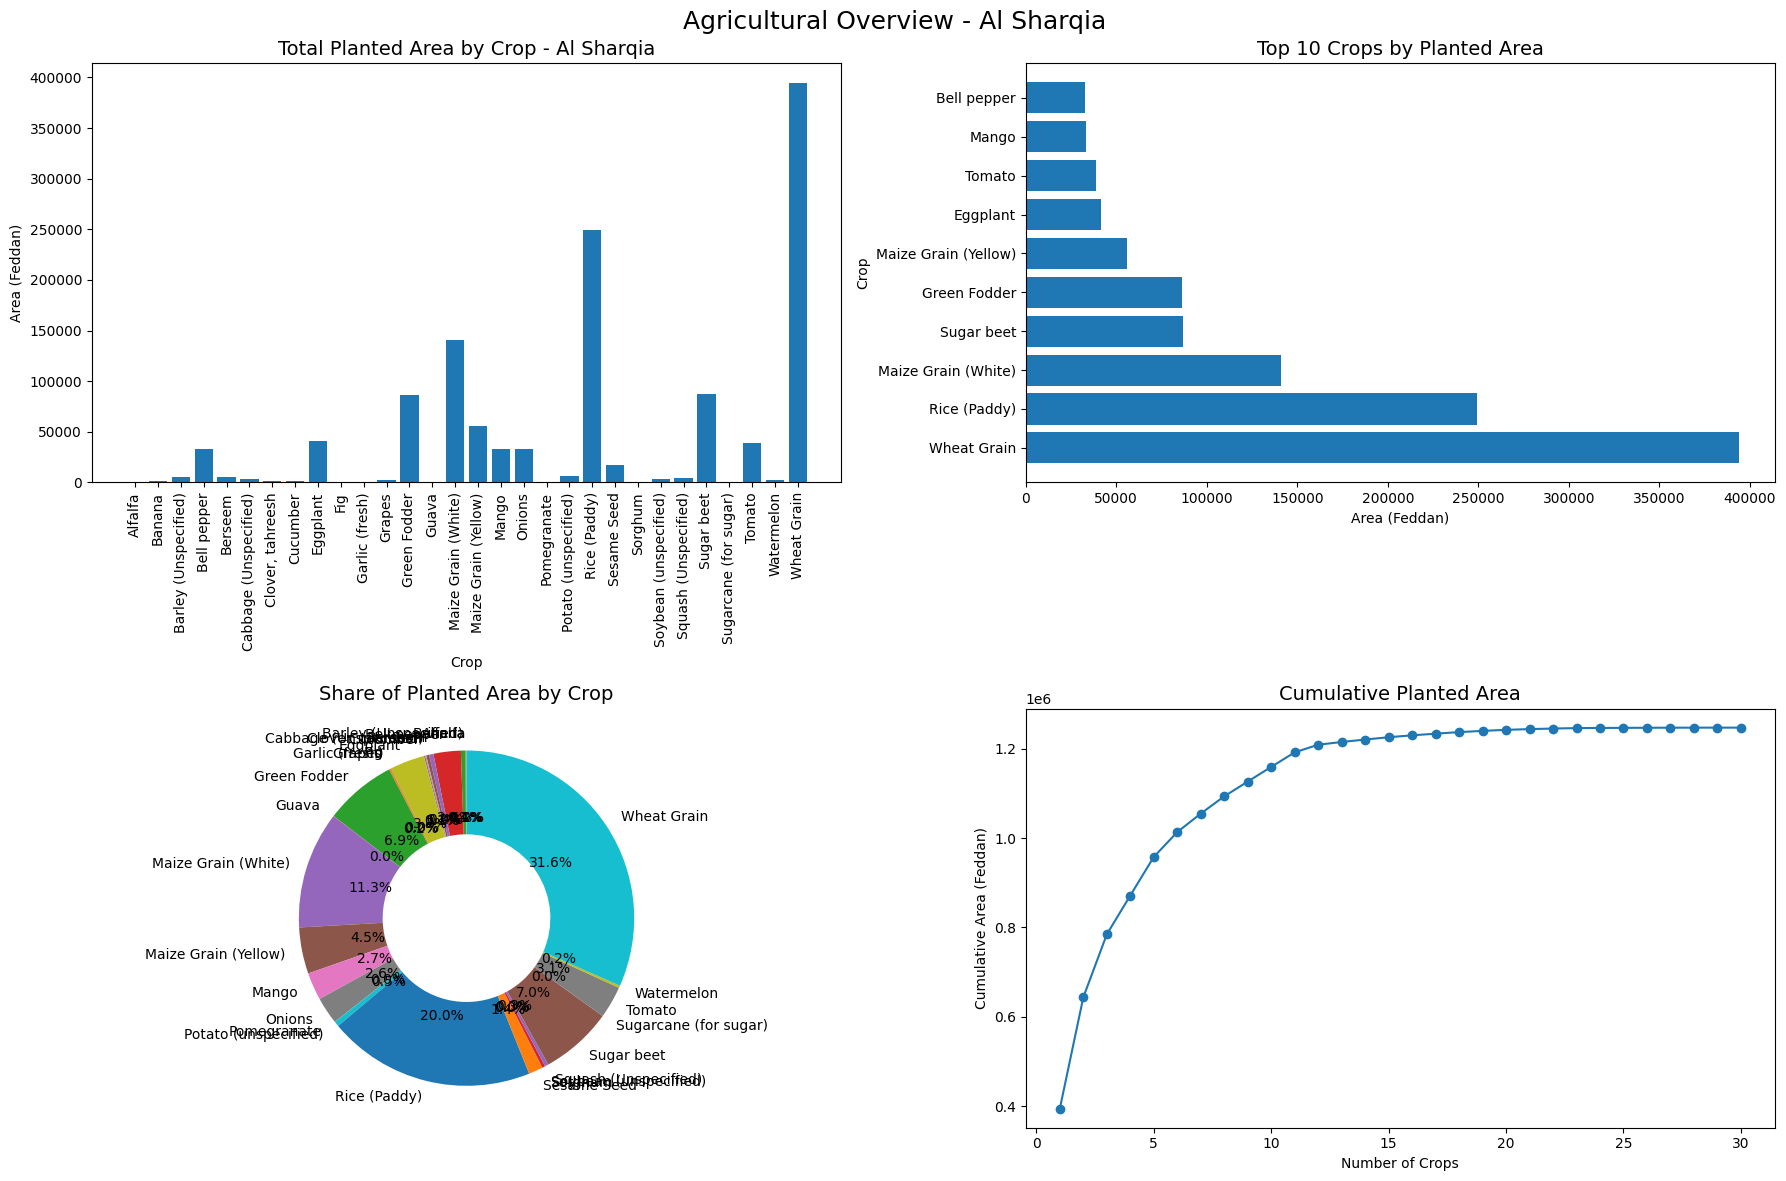

In [15]:

city = df[df["governorate"] == "Al Sharqia"]

data_city = city.groupby("product")["area_feddan"].sum()

products = data_city.index.to_numpy()
quantity = data_city.values


data_city = data_city.sort_values(ascending=False)

top10 = data_city.head(10)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))


# ==========================================
# all crop
# ==========================================

axes[0, 0].bar(products, quantity)

axes[0, 0].set_title(
    "Total Planted Area by Crop - Al Sharqia",
    fontsize=14
)

axes[0, 0].set_xlabel("Crop")
axes[0, 0].set_ylabel("Area (Feddan)")

axes[0, 0].tick_params(
    axis="x",
    rotation=90
)


# ==========================================
# 2. Top 10 Crops
# ==========================================

axes[0, 1].barh(
    top10.index,
    top10.values
)

axes[0, 1].set_title(
    "Top 10 Crops by Planted Area",
    fontsize=14
)

axes[0, 1].set_xlabel("Area (Feddan)")
axes[0, 1].set_ylabel("Crop")


# ==========================================
# 3. pie
# ==========================================

#other = data_city.iloc[10:].sum()

#donut_data = pd.concat([
#    top10,
#    pd.Series({"Other": other})
#])
axes[1, 0].pie(
    quantity,
    labels=products,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.5)
)

axes[1, 0].set_title(
    "Share of Planted Area by Crop",
    fontsize=14
)


# ==========================================
# 4. Cumulative Area
# ==========================================

cumulative = data_city.cumsum()

axes[1, 1].plot(
    range(1, len(cumulative) + 1),
    cumulative.values,
    marker="o"
)

axes[1, 1].set_title(
    "Cumulative Planted Area",
    fontsize=14
)

axes[1, 1].set_xlabel("Number of Crops")
axes[1, 1].set_ylabel("Cumulative Area (Feddan)")


plt.suptitle(
    "Agricultural Overview - Al Sharqia",
    fontsize=18
)

plt.tight_layout()

plt.show()

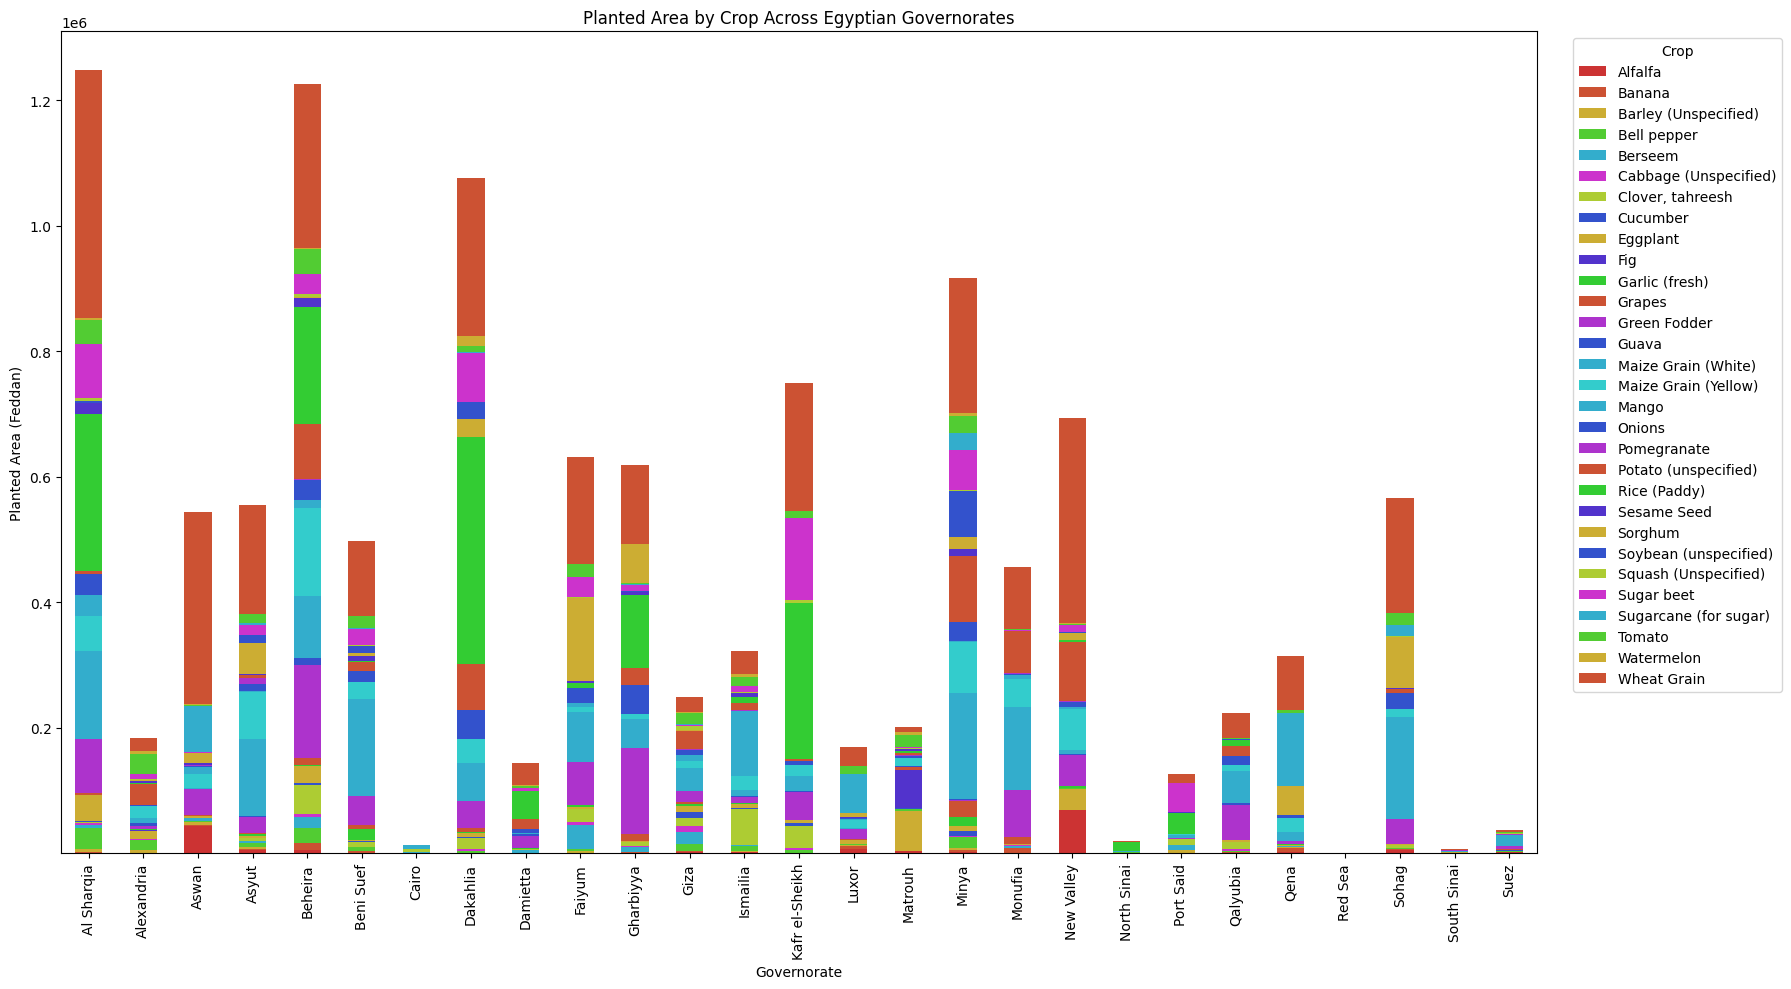

In [16]:
data = df.groupby(
    ["governorate", "product"]
)["area_feddan"].sum()

data = data.unstack(fill_value=0)
n = len(data.columns)

colors = []

for i in range(n):
    hue = i*i/ n
    rgb = colorsys.hsv_to_rgb(hue, 0.75, 0.8)
    colors.append(rgb)


data.plot(
    kind="bar",
    stacked=True,
    figsize=(18, 10),
    color=colors
)


plt.xlabel("Governorate")
plt.ylabel("Planted Area (Feddan)")
plt.title("Planted Area by Crop Across Egyptian Governorates")

plt.xticks(rotation=90)

plt.legend(
    title="Crop",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

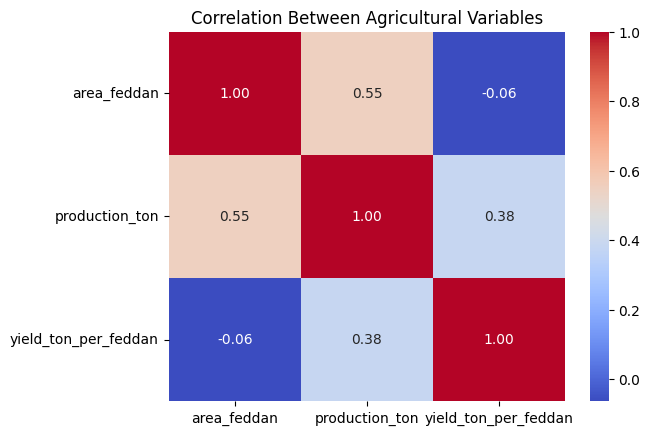

In [17]:
corr = df[
    ["area_feddan", "production_ton", "yield_ton_per_feddan"]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Agricultural Variables")
plt.show()

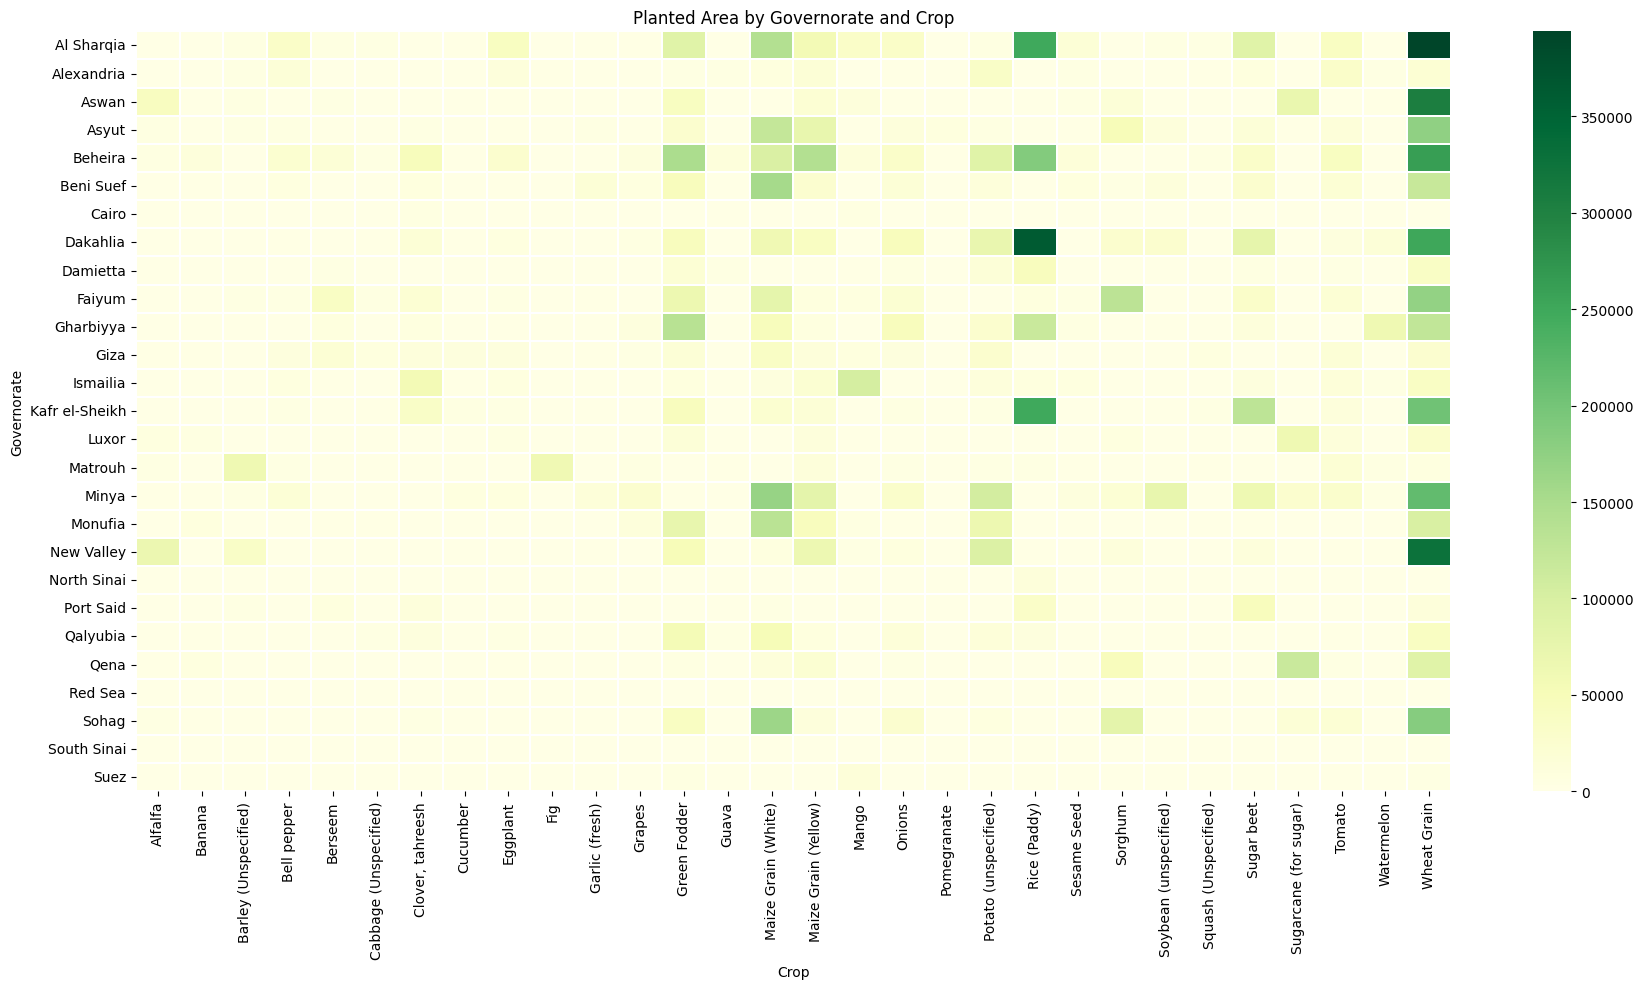

In [18]:
heatmap_data = df.pivot_table(
    index="governorate",
    columns="product",
    values="area_feddan",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(18, 10))

sns.heatmap(
    heatmap_data,
    cmap="YlGn",
    linewidths=0.3
)

plt.title("Planted Area by Governorate and Crop")
plt.xlabel("Crop")
plt.ylabel("Governorate")

plt.tight_layout()
plt.show()

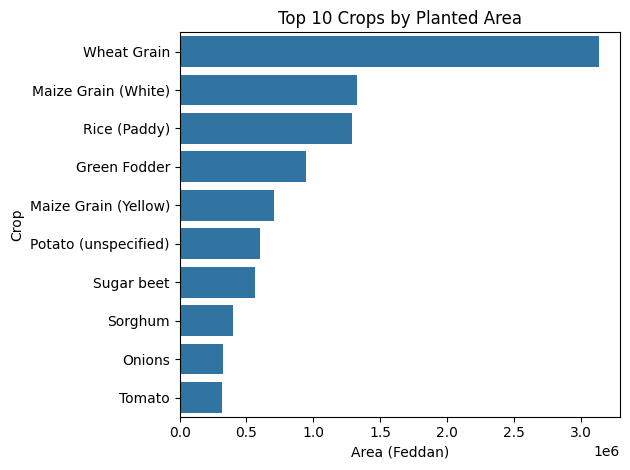

In [19]:
top_products = (
    df.groupby("product")["area_feddan"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

sns.barplot(
    data=top_products,
    x="area_feddan",
    y="product"
)

plt.title("Top 10 Crops by Planted Area")
plt.xlabel("Area (Feddan)")
plt.ylabel("Crop")

plt.tight_layout()
plt.show()

In [20]:
from branca.colormap import linear

selected_product = "Wheat Grain"
product_data = df[df["product"] == selected_product]
area_data = product_data.groupby(
    "governorate"
)["area_feddan"].sum()
#map
m = folium.Map(
    location=[27.5, 30.8],
    zoom_start=6.4
)
# ==========================================
# Color Scale
# ==========================================

colormap = linear.YlGn_09.scale(
    area_data.min(),
    area_data.max()
)

colormap.caption = f"Planted Area - {selected_product} (Feddan)"

colormap.add_to(m)


# ==========================================
# رسم المحافظات
# ==========================================

for _, row in df[
    ["governorate", "latitude", "longitude"]
].drop_duplicates().iterrows():

    governorate = row["governorate"]

    area = area_data.get(governorate, 0)

    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],

        radius=10,

        color="black",

        fill=True,

        fill_color=colormap(area),

        fill_opacity=0.8,

        popup=folium.Popup(
            f"""
            <b>Governorate:</b> {governorate}<br>
            <b>Crop:</b> {selected_product}<br>
            <b>Planted Area:</b> {area:,.2f} Feddan
            """,
            max_width=300
        ),

        tooltip=f"{governorate}: {area:,.0f} Feddan"

    ).add_to(m)


m

In [21]:
import folium


# ======================================
# اختيار المحصول
# ======================================

selected_product = "Wheat Grain"


# ======================================
# بيانات المحصول
# ======================================

crop_data = df[df["product"] == selected_product]

governorate_data = crop_data.groupby(
    "governorate"
)["area_feddan"].sum()


# ======================================
# دالة تحديد اللون
# ======================================

def get_color(area, max_area):

    percentage = area / max_area

    if percentage >= 0.75:
        return "darkgreen"

    elif percentage >= 0.50:
        return "green"

    elif percentage >= 0.25:
        return "lightgreen"

    elif percentage > 0:
        return "orange"

    else:
        return "red"


# ======================================
# أكبر مساحة
# ======================================

max_area = governorate_data.max()


# ======================================
# خريطة مصر
# ======================================

m = folium.Map(
    location=[27.5, 30.8],
    zoom_start=6
)


# ======================================
# رسم المحافظات
# ======================================

locations = df[
    ["governorate", "latitude", "longitude"]
].drop_duplicates()


for _, location in locations.iterrows():

    governorate = location["governorate"]

    area = governorate_data.get(governorate, 0)

    color = get_color(area, max_area)

    # حجم الدائرة حسب المساحة
    radius = 5 + (area / max_area) * 20

    folium.CircleMarker(

        location=[
            location["latitude"],
            location["longitude"]
        ],

        radius=radius,

        color=color,

        fill=True,

        fill_color=color,

        fill_opacity=0.7,

        popup=f"""
        <b>Governorate:</b> {governorate}<br>
        <b>Crop:</b> {selected_product}<br>
        <b>Planted Area:</b> {area:,.2f} Feddan
        """,

        tooltip=f"{governorate} - {area:,.0f} Feddan"

    ).add_to(m)


m

In [22]:
url = "https://services1.arcgis.com/dRxtwawTOPZm6CPj/ArcGIS/rest/services/egypt_governorates/FeatureServer/0/query?where=1%3D1&outFields=*&outSR=4326&f=geojson"

response = requests.get(url)

#print("Status Code:", response.status_code)

geojson = response.json()
for feature in geojson["features"]:
    old_name = feature["properties"]["NAME_1"]

    feature["properties"]["governorate"] = geojson_map.get(
        old_name,
        old_name
    )


selected_product = "Wheat Grain"


crop_data = df[df["product"] == selected_product]


# ======================================
# إجمالي المساحة لكل محافظة
# ======================================

governorate_area = (
    crop_data
    .groupby("governorate")["area_feddan"]
    .sum()
    .reset_index()
)


#print(governorate_area)


m = folium.Map(
    location=[27.5, 30.8],
    zoom_start=6
)


# ======================================
# Choropleth
# ======================================

folium.Choropleth(

    geo_data=geojson,

    name=selected_product,

    data=governorate_area,

    columns=[
        "governorate",
        "area_feddan"
    ],

    key_on="feature.properties.governorate",
    fill_color="YlGn",

    fill_opacity=0.7,

    line_opacity=0.3,

    legend_name=f"{selected_product} - Planted Area (Feddan)",

    nan_fill_color="lightgray"

).add_to(m)


# ======================================
# Layer Control
# ======================================

folium.LayerControl().add_to(m)
m

SSLError: HTTPSConnectionPool(host='services1.arcgis.com', port=443): Max retries exceeded with url: /dRxtwawTOPZm6CPj/ArcGIS/rest/services/egypt_governorates/FeatureServer/0/query?where=1%3D1&outFields=*&outSR=4326&f=geojson (Caused by SSLError(SSLEOFError(8, '[SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1000)')))